# Лабораторная работа №1: Microsoft Learn

## 1. Получение примеров

Сырой документ представляет собой HTML-страницу. Адреса документации я получаю из [индекса sitemap Microsoft Learn](https://learn.microsoft.com/_sitemaps/sitemapindex.xml). Я выбираю только англоязычные страницы `/en-us/`, исключаю справочник API и архив старых версий, затем проверяю объём уже очищенного основного текста. Страницы выбираются поочерёдно из разных продуктовых разделов до получения 30 документов. Примеры сохраняются в каталоге проекта `data/microsoft_learn_sample.json`.

In [1]:
from pathlib import Path
import json
import re
import time
import xml.etree.ElementTree as ET

from bs4 import BeautifulSoup
import matplotlib.pyplot as plt
import pandas as pd
import requests

SITEMAP_INDEX = 'https://learn.microsoft.com/_sitemaps/sitemapindex.xml'
SAMPLE_PRODUCTS = [
    'azure', 'sql', 'windows', 'linux', 'security', 'power-bi',
    'devops', 'cosmos-db', 'semantic-kernel', 'cpp', 'defender', 'ai',
]
MIN_WORDS = 250
SAMPLE_SIZE = 30
DATA_DIR = Path('..') / 'data'
SAMPLE_FILE = DATA_DIR / 'microsoft_learn_sample.json'
DATA_DIR.mkdir(exist_ok=True)

session = requests.Session()
session.headers['User-Agent'] = 'MAI-IR-course-project/1.0 (educational corpus analysis)'

In [2]:
def xml_locations(content):
    root = ET.fromstring(content.decode('utf-8-sig'))
    return [node.text.strip() for node in root.iter() if node.tag.endswith('loc') and node.text]

def suitable_url(url):
    excluded = (
        '/answers/', '/shows/', '/events/', '/users/', '/credentials/',
        '/api/', '/previous-versions/',
    )
    return url.startswith('https://learn.microsoft.com/en-us/') and not any(part in url for part in excluded)

def extract_clean_main_text(html):
    soup = BeautifulSoup(html, 'lxml')
    main = soup.select_one('main')
    if main is None:
        return ''
    for node in main.select(
        'script, style, nav, aside, footer, button, .notification, '
        '#article-header, #article-metadata, #site-user-feedback-footer, .doc-outline'
    ):
        node.decompose()
    blocks = [node.get_text(' ', strip=True) for node in main.select('h1, h2, h3, p, li, pre, table')]
    return re.sub(r'\s+', ' ', ' '.join(blocks)).strip()

def download_microsoft_learn_sample():
    response = session.get(SITEMAP_INDEX, timeout=60)
    response.raise_for_status()
    sitemap_urls = xml_locations(response.content)
    sitemaps_by_product = {}
    for sitemap_url in sitemap_urls:
        filename = sitemap_url.rsplit('/', 1)[-1]
        if '_en-us_' not in filename:
            continue
        product = filename.split('_en-us_', 1)[0]
        sitemaps_by_product.setdefault(product, []).append(sitemap_url)

    product_urls = {}
    for product in SAMPLE_PRODUCTS:
        urls = []
        for sitemap_url in sitemaps_by_product.get(product, [])[:3]:
            try:
                sitemap_response = session.get(sitemap_url, timeout=60)
                sitemap_response.raise_for_status()
                urls.extend(url for url in xml_locations(sitemap_response.content) if suitable_url(url))
            except requests.RequestException:
                continue
        product_urls[product] = list(dict.fromkeys(urls))

    documents = []
    seen_urls = set()
    positions = {product: 0 for product in SAMPLE_PRODUCTS}
    while len(documents) < SAMPLE_SIZE:
        documents_before_round = len(documents)
        for product in SAMPLE_PRODUCTS:
            urls = product_urls[product]
            while positions[product] < len(urls):
                url = urls[positions[product]]
                positions[product] += 1
                if url in seen_urls:
                    continue
                seen_urls.add(url)
                try:
                    page = session.get(url, timeout=60)
                    page.raise_for_status()
                except requests.RequestException:
                    continue
                time.sleep(0.25)
                clean_text = extract_clean_main_text(page.text)
                if len(clean_text.split()) >= MIN_WORDS:
                    documents.append({'product': product, 'url': page.url, 'html': page.text})
                    break
            if len(documents) == SAMPLE_SIZE:
                break
        if len(documents) == documents_before_round:
            break
    return documents

if SAMPLE_FILE.exists():
    raw_documents = json.loads(SAMPLE_FILE.read_text(encoding='utf-8'))
else:
    raw_documents = download_microsoft_learn_sample()
    SAMPLE_FILE.write_text(json.dumps(raw_documents, ensure_ascii=False, indent=2), encoding='utf-8')

print(f'Скачано документов: {len(raw_documents)}')
print(f'Файл с примерами: {SAMPLE_FILE}')

Скачано документов: 30
Файл с примерами: ../data/microsoft_learn_sample.json


## 2. Выделение текста и метаданных

Основной материал страницы расположен в элементе `main`. Я удаляю навигацию, кнопки, скрипты, стили и служебные блоки. Из метатегов сохраняю описание, автора, дату и канонический URL.

In [3]:
def meta_content(soup, name):
    node = soup.find('meta', attrs={'name': name})
    return node.get('content') if node else None

def parse_learn_page(raw):
    soup = BeautifulSoup(raw['html'], 'lxml')
    text = extract_clean_main_text(raw['html'])
    title_node = soup.select_one('h1') or soup.select_one('title')
    canonical = soup.find('link', rel='canonical')
    return {
        'source_id': meta_content(soup, 'document_id') or raw['url'],
        'product': raw['product'],
        'title': title_node.get_text(' ', strip=True) if title_node else '',
        'url': canonical.get('href') if canonical else raw['url'],
        'description': meta_content(soup, 'description'),
        'author': meta_content(soup, 'author'),
        'date': meta_content(soup, 'ms.date'),
        'text': text,
        'raw_size': len(raw['html'].encode('utf-8')),
        'text_size': len(text.encode('utf-8')),
        'word_count': len(text.split()),
    }

documents = [parse_learn_page(raw) for raw in raw_documents]
frame = pd.DataFrame(documents)
frame[['product', 'title', 'author', 'date', 'word_count', 'raw_size', 'text_size', 'url']]

,product,title,author,date,word_count,raw_size,text_size,url
0,azure,Dldsv6 sizes series,mattmcinnes,2026-03-10T00:00:00Z,1401,64793,9098,https://learn.microsoft.com/en-us/azure/virtua...
1,sql,SQL MCP Server documentation,JerryNixon,2025-12-22T00:00:00Z,251,34171,1691,https://learn.microsoft.com/en-us/sql/mcp/
2,windows,How to create a custom App Installer experience,larhu,2021-09-30T00:00:00Z,532,51503,4177,https://learn.microsoft.com/en-us/windows/msix...
3,linux,How to download and install Linux,fossygirl,2024-01-22T00:00:00Z,2874,69964,17460,https://learn.microsoft.com/en-us/linux/install
4,security,Interact with Project Perception using chat,mjcaparas,2026-07-31T00:00:00Z,550,51350,3481,https://learn.microsoft.com/en-us/security/age...
5,power-bi,Microsoft Fabric adoption roadmap: Content own...,dknappettmsft,2024-12-30T00:00:00Z,3930,85245,25581,https://learn.microsoft.com/en-us/power-bi/gui...
6,devops,Introduction to operating reliable systems wit...,BillWagner,2022-07-18T00:00:00Z,262,49693,1727,https://learn.microsoft.com/en-us/devops/opera...
7,cosmos-db,Index vector data in Cosmos DB (in Azure and F...,seesharprun,2026-05-22T00:00:00Z,2149,61456,14273,https://learn.microsoft.com/en-us/cosmos-db/in...
8,semantic-kernel,AgentGroupChat Orchestration Migration Guide,taochen,2025-05-21T00:00:00Z,1049,49803,9384,https://learn.microsoft.com/en-us/semantic-ker...
9,cpp,class Translation::TranslationRecognizer,BrianMouncer,2025-03-20T00:00:00Z,961,48445,7916,https://learn.microsoft.com/en-us/cpp/cognitiv...


## 3. Статистика выборки

In [4]:
statistics = pd.Series({
    'Количество документов': len(frame),
    'Размер сырых документов, байт': int(frame.raw_size.sum()),
    'Размер выделенного текста, байт': int(frame.text_size.sum()),
    'Средний размер сырого документа, байт': round(frame.raw_size.mean(), 2),
    'Средний размер текста, байт': round(frame.text_size.mean(), 2),
    'Среднее количество слов': round(frame.word_count.mean(), 2),
})
statistics

Количество документов                         30.00
Размер сырых документов, байт            1770272.00
Размер выделенного текста, байт           307385.00
Средний размер сырого документа, байт      59009.07
Средний размер текста, байт                10246.17
Среднее количество слов                     1474.33
dtype: float64

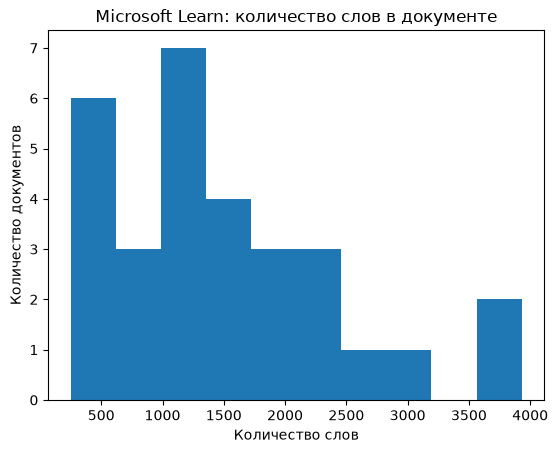

In [5]:
frame.word_count.plot.hist(bins=10, title='Microsoft Learn: количество слов в документе')
plt.xlabel('Количество слов')
plt.ylabel('Количество документов')
plt.show()

## 4. Существующий поиск

Примеры запросов: [site:learn.microsoft.com vector search HNSW](https://www.google.com/search?q=site%3Alearn.microsoft.com+vector+search+HNSW) и [site:learn.microsoft.com python async memory](https://www.google.com/search?q=site%3Alearn.microsoft.com+python+async+memory).

| Запрос | Наблюдение | Недостаток |
|---|---|---|
| `vector search HNSW` | Находится документация Azure AI Search о векторных индексах | Рядом могут быть страницы разных продуктов, версий и справочника API |
| `python async memory` | Находятся материалы о Python и асинхронном программировании | Неоднозначные термины смешивают несколько продуктов и типов документации |

По моим наблюдениям, результат зависит от актуальности внешнего поискового индекса. В HTML встречаются повторяющиеся навигационные и служебные блоки, поэтому их необходимо удалять перед индексацией.

## Вывод

Microsoft Learn добавляет в корпус практические инструкции, примеры кода и описания программных продуктов. Этот источник дополняет энциклопедические статьи Wikipedia и научные публикации arXiv.